# Bilayer Wigner Crystal: Finding the Ground-State Lattice by Optimization

**Goal.** Reproduce the main result of Fig. 1 of G. Goldoni and F. M. Peeters,
*"Stability, dynamical properties, and melting of a classical bilayer Wigner crystal,"*
Phys. Rev. B **53**, 4591–4603 (1996),
[doi:10.1103/PhysRevB.53.4591](https://doi.org/10.1103/PhysRevB.53.4591): the static Coulomb
energy per particle of a classical bilayer Wigner crystal as a function of the dimensionless
interlayer parameter $\eta = d\sqrt{n/2}$ ($d$ is the interlayer distance, $n$ the total areal
density) — without assuming any lattice geometry in advance.

**What this tutorial covers:**
- Building a fully general, non-hardcoded oblique-cell parameterization for a two-particle bilayer
  unit cell
- Using JAX autodiff and `optax` to find, by gradient descent, the cell shape *and* the two
  electron positions that minimize the Coulomb energy computed with
  `ezwald.bilayer_sum.EwaldSumSlab`
- Validating the result against the paper's own closed-form limits and its three rigid candidate
  lattices (Table I, phases I, III and V) — reproduced here from the table, not assumed by the
  optimizer — with energy comparisons for the soft phases II and IV
- Checking that the optimizer recovers not just the right energy but the right lattice geometry,
  using 2D lattice ("Lagrange") reduction to compare bases independent of orientation

The paper's own approach is to write down five candidate lattices and compare their energies by
hand. Here, the optimizer is given only two starting particle positions (one per layer, otherwise
arbitrary) and a value of $\eta$, and is left to discover the ground-state structure on its own.

**Contents:** 1-4 method, 5 sanity checks, 6 $\eta$ sweep, 7 assumed reference curves, 8
comparison chart, 9 do the optimized structures match the assumed lattices, 10 the optimizer also
finds the soft phases.

**Requirements:** `ezwald`, `jax`, `optax`, `numpy`, `matplotlib`. Runs in a couple of minutes on CPU.

In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'
import jax
jax.config.update("jax_enable_x64", True)

import numpy as np
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt

from ezwald import bilayer_sum, geometry as geo

np.set_printoptions(precision=6, suppress=True)

## 1. Physical conventions

We follow the paper's conventions: total areal density $n=1$, $e=1$, so the energy per particle
computed by EZwald is directly the dimensionless quantity $E/(e^2\sqrt n)$ plotted in the paper's Fig. 1.

The bilayer's primitive cell holds exactly **one particle per layer** (Eqs. 1-2 of the paper), so
for a given total density $n$ the in-plane cell area is fixed by

$$
n_s = n/2 = \frac{1}{A_{\text{cell}}} \quad\Rightarrow\quad A_{\text{cell}} = \frac{2}{n},
$$

and the interlayer distance for a target $\eta$ is $d = \eta/\sqrt{n_s}$. This area constraint is
the *only* physics we build in by hand — it fixes the density, not the lattice shape. Everything
about the shape of the cell and the relative position of the two particles is left to the
optimizer.

In [2]:
n_total = 1.0                 # total areal density n (both layers), e = 1
n_s = n_total / 2.0            # density of each sublattice
area = 2.0 / n_total           # in-plane primitive-cell area fixed by n_s = 1/area
aref = float(np.sqrt(area))    # a reference length scale, used only to set search ranges

def eta_to_d(eta):
    return eta / np.sqrt(n_s)

## 2. A generic (non-hardcoded) parameterization of the bilayer cell

Instead of picking one of the five named Bravais lattices, we describe *any* 2D oblique cell of
fixed area with two free numbers, $a$ and $\theta$:

$$
\mathbf a_1 = (a,\,0), \qquad
\mathbf a_2 = (b\cos\theta,\, b\sin\theta), \qquad
b = \frac{A_{\text{cell}}}{a\sin\theta},
$$

so that $|\mathbf a_1\times\mathbf a_2| = A_{\text{cell}}$ exactly, for *any* choice of $a,\theta$.
This single family already contains all five of the paper's phases as special cases (e.g.
$\theta=90^\circ$ with the right $a$ gives the rectangular phases I/II/III; $\theta=60^\circ$
gives the hexagonal phases). We never tell the optimizer which one to pick.

The two particle positions — one per layer — are stored as free **fractional** coordinates
`pos_frac`, shape `(2, 2)`, converted to Cartesian via `pos_frac @ cell`. `pos_frac[0]` is the
layer-A particle, `pos_frac[1]` is the layer-B particle; nothing pins either of them to a
particular value.

`a` and `theta` are optimized in an unconstrained space and mapped through a `sigmoid` into a
generous-but-finite range. This is *not* a physics assumption about which phase wins — it only
keeps the cell from collapsing into a numerically degenerate sliver during gradient descent (an
Ewald sum's real/reciprocal split becomes ill-conditioned for extremely skewed cells). The range
is wide enough to contain the lattices of phases I, III and V, and we verify that below by checking
that the optimizer recovers their energies from Table I. For the soft phases II and IV we compare
only energies (Section 10), not their lattice parameters.

In [3]:
THETA_MIN, THETA_MAX = jnp.deg2rad(40.0), jnp.deg2rad(140.0)
A_MIN, A_MAX = 0.55 * aref, 1.8 * aref

def unpack_params(params):
    '''Map unconstrained (raw_a, raw_theta) into a bounded, well-conditioned cell.'''
    a = A_MIN + (A_MAX - A_MIN) * jax.nn.sigmoid(params['raw_a'])
    theta = THETA_MIN + (THETA_MAX - THETA_MIN) * jax.nn.sigmoid(params['raw_theta'])
    return a, theta, params['pos_frac']

def make_cell(area, a, theta):
    '''Build a fixed-area oblique cell from free parameters (a, theta).'''
    b = area / (a * jnp.sin(theta))
    return jnp.stack([
        jnp.stack([a, 0.0 * a]),
        jnp.stack([b * jnp.cos(theta), b * jnp.sin(theta)]),
    ])

def random_init(key):
    '''Random starting guess: unconstrained (a, theta) plus two random fractional positions.'''
    k1, k2, k3 = jax.random.split(key, 3)
    raw_a = jax.random.uniform(k1, (), minval=-1.5, maxval=1.5)
    raw_theta = jax.random.uniform(k2, (), minval=-1.5, maxval=1.5)
    pos_frac = jax.random.uniform(k3, (2, 2))  # the two starting positions, one per layer
    return {'raw_a': raw_a, 'raw_theta': raw_theta, 'pos_frac': pos_frac}

## 3. Energy of a candidate configuration

Given `params` (cell shape + the two positions) and the interlayer distance `d` for this $\eta$, the loss is the dimensionless bilayer Coulomb energy per particle from EZwald's `bilayer_sum.EwaldSumSlab`, evaluated on a cell and positions that come from the optimizer rather than from a table of lattice vectors.

Two implementation details make this differentiable and numerically stable while the cell keeps changing shape during gradient descent:

* **Reciprocal G-vectors as `gidx @ recvec(cell)`.** `EwaldSumSlab`'s own G-point selection does a boolean-mask filter, which is not differentiable/vmappable. We instead pick the integer G indices once (from a reference cell), then recompute the actual G-vectors from the *current* cell at every step — differentiable, and cheap.
* **A fixed Ewald `alpha`,** also taken from the reference cell rather than re-guessed from whatever (possibly transiently skewed) cell the optimizer is currently visiting. Letting `alpha` auto-adjust to a mid-optimization degenerate cell was, in practice, the difference between a stable convergent energy and spurious large-negative numerical artifacts.

In [4]:
charge = -jnp.ones(2)  # both particles carry charge -1 (in units of e)

def build_ewald_reference(d, n_lat=2):
    '''Pick a reference (square, well-conditioned) cell just to fix the G-index set and alpha.'''
    cell0 = np.array([[aref, 0.0], [0.0, aref]])
    trial = bilayer_sum.EwaldSumSlab(cell0, float(d), disp_fn_mode='general', n_lat=n_lat)
    recvec0 = geo.calc_recvec(jnp.asarray(cell0))
    gidx = np.array(np.round(trial.gpoints @ np.linalg.inv(np.asarray(recvec0))), dtype=int)
    return jnp.asarray(gidx), float(trial.alpha)

def make_loss(d, gidx, alpha, n_lat=2):
    def loss_fn(params):
        a, theta, pos_frac = unpack_params(params)
        cell = make_cell(area, a, theta)
        recvec = geo.calc_recvec(cell)
        gpoints = gidx @ recvec  # differentiable w.r.t. the current cell
        bew = bilayer_sum.EwaldSumSlab(
            cell, d, disp_fn_mode='general', gpoints=gpoints, alpha=alpha, n_lat=n_lat,
        )
        pos = pos_frac @ cell  # fractional -> Cartesian, for BOTH layer positions
        E_total = bew.energy(charge, pos)
        return (E_total / 2.0) / jnp.sqrt(n_total)  # E per particle, dimensionless
    return loss_fn

## 4. Optimizing at a single $\eta$

Gradient descent from one starting pair of positions only ever finds *a* local minimum — and
since we've deliberately not told it which phase to expect, that local minimum could belong to
any of the (generally several) locally-stable geometries at this $\eta$. So for each $\eta$ we
launch several independent optimizations from different random starting positions and cell shapes,
run each with Adam (exponential-decay learning-rate schedule, gradient clipping), and keep whichever
run reaches the lowest energy. This is a
basin-hopping-style global search standing in for prior knowledge of the phase diagram — the
sweep over restarts is what lets the true equilibrium structure emerge on its own.

All restarts for a given $\eta$ are optimized simultaneously with a single `vmap`+`jit`'d
`lax.scan`, so the whole batch of gradient-descent trajectories runs as one compiled call.

In [5]:
def optimize_eta(eta, key, n_restarts=8, nstep=500):
    '''Relax the bilayer cell + two positions at fixed eta; return the lowest energy found.'''
    d = eta_to_d(eta)
    gidx, alpha = build_ewald_reference(d)
    loss_fn = make_loss(d, gidx, alpha)
    grad_fn = jax.value_and_grad(loss_fn)

    schedule = optax.exponential_decay(init_value=0.1, transition_steps=200, decay_rate=0.5)
    optimizer = optax.chain(optax.clip(1.0), optax.adam(schedule))

    def run_opt(params, opt_state):
        def scan_step(carry, _):
            params, opt_state = carry
            _, grads = grad_fn(params)
            updates, opt_state = optimizer.update(grads, opt_state, params)
            params = optax.apply_updates(params, updates)
            return (params, opt_state), None
        (params, opt_state), _ = jax.lax.scan(scan_step, (params, opt_state), None, length=nstep)
        return params

    keys = jax.random.split(key, n_restarts)
    params0 = jax.vmap(random_init)(keys)               # the batch of "2 starting positions" + cells
    opt_state0 = jax.vmap(optimizer.init)(params0)

    final_params = jax.jit(jax.vmap(run_opt))(params0, opt_state0)
    final_energy = jax.vmap(loss_fn)(final_params)
    final_energy = jnp.where(jnp.isnan(final_energy), jnp.inf, final_energy)
    best = jnp.argmin(final_energy)
    return float(final_energy[best]), final_params, best

## 5. Sanity checks against the paper's known closed-form limits

Before sweeping the full range, we check the optimizer against two limits where the paper gives
closed-form energies — with no lattice hardcoded anywhere in the optimization itself:

* $\eta\to0$: should approach the single-layer hexagonal Wigner crystal value $E/(e^2\sqrt n)=-1.96052$. We test at $\eta=0.001$, not exactly 0, so the paper's small-$\eta$ series (Eq. 16) gives the expected value there.
* $\eta\to\infty$: two decoupled hexagonal lattices of half density, $E/(e^2\sqrt n)\to-1.96052/\sqrt2\approx-1.38630$.

In [6]:
def eq16(eta):
    '''Small-eta series for the energy per particle, Eq. 16 of the paper.'''
    return -1.96052 + (1 / (2 * np.sqrt(2))) * (2 * np.pi * eta - 0.600434 * eta**2 + 2.86713 * eta**4)

key = jax.random.PRNGKey(0)

k1, key = jax.random.split(key)
e_small, _, _ = optimize_eta(0.001, k1)
print(f"eta=0.001 (-> eta=0 limit):   optimized = {e_small:.5f}   paper Eq. 16 = {eq16(0.001):.5f}   (eta=0 value: -1.96052)")

k1, key = jax.random.split(key)
e_large, _, _ = optimize_eta(10.0, k1)
print(f"eta=10    (-> eta=inf limit): optimized = {e_large:.5f}   asymptote = {-1.96052/np.sqrt(2):.5f}")

eta=0.001 (-> eta=0 limit):   optimized = -1.95830   paper Eq. 16 = -1.95830   (eta=0 value: -1.96052)
eta=10    (-> eta=inf limit): optimized = -1.38629   asymptote = -1.38630


The $\eta\to\infty$ limit is reproduced to about 5 significant figures (compare the two printed values). At small $\eta$ the optimized energy sits slightly above the $\eta=0$ value (by ~0.1%), which is the finite-$\eta$ effect rather than an error: the paper's small-$\eta$ series (Eq. 16), printed alongside, agrees with the optimizer to about the printed precision. In both cases the optimizer was given nothing but two arbitrary starting positions and a (deliberately loose) bound on cell shape.

## 6. Sweeping $\eta$

We sweep $\eta$ from 0.01 to 1 (the range plotted in the paper's Fig. 1; we start just above 0 because $\eta=0$ puts both layers on top of each other, a degenerate starting point) using 40 points, and optimize at each one.

In [7]:
eta_opt = np.linspace(0.01, 1.0, 40)

energies_opt = np.zeros_like(eta_opt)
key = jax.random.PRNGKey(1)
for i, eta in enumerate(eta_opt):
    key, subkey = jax.random.split(key)
    energies_opt[i], _, _ = optimize_eta(eta, subkey)

print("done:", len(eta_opt), "eta points optimized")

done: 40 eta points optimized


## 7. Assumed reference curves from Table I of the paper

For comparison we also compute the energy of the paper's three *rigid* phases — I (one-component hexagonal), III (staggered square) and V (staggered hexagonal) — directly from the primitive vectors $\mathbf a_1,\mathbf a_2$ and interlayer displacement $\mathbf c$ tabulated in Table I. This part *does* hardcode the lattice geometry, because that is what Table I is; its only purpose is to draw the comparison curves, and it plays no role in the optimization above. (Phases II and IV have a free aspect ratio/angle that the paper minimizes separately, so there is no single fixed geometry to tabulate for them.)

In [8]:
PHASE_TABLE = {
    "I": dict(
        a1=lambda a: np.array([a, 0.0]),
        a2=lambda a: np.array([0.0, np.sqrt(3) * a]),
        c=lambda a1, a2: (a1 + a2) / 2,
        nsa2=1 / np.sqrt(3),
        label="I. One-component hexagonal",
    ),
    "III": dict(
        a1=lambda a: np.array([a, 0.0]),
        a2=lambda a: np.array([0.0, a]),
        c=lambda a1, a2: (a1 + a2) / 2,
        nsa2=1.0,
        label="III. Staggered square",
    ),
    "V": dict(
        a1=lambda a: np.array([a, 0.0]),
        a2=lambda a: np.array([0.5 * a, np.sqrt(3) / 2 * a]),
        c=lambda a1, a2: (a1 + a2) / 3,
        nsa2=2 / np.sqrt(3),
        label="V. Staggered hexagonal",
    ),
}


def build_phase_cell(phase, n_total=1.0):
    entry = PHASE_TABLE[phase]
    n_s = n_total / 2.0
    a = np.sqrt(entry["nsa2"] / n_s)
    a1 = entry["a1"](a)
    a2 = entry["a2"](a)
    c = entry["c"](a1, a2)
    return np.array([a1, a2]), c, a


def reference_dimensionless_energy(phase, eta, n_total=1.0):
    latvec, c, a = build_phase_cell(phase, n_total=n_total)
    n_s = n_total / 2.0
    d = eta / np.sqrt(n_s)
    bew = bilayer_sum.EwaldSumSlab(latvec, float(d))
    pos = jnp.array([[0.0, 0.0], c])
    ch = -jnp.ones(2)
    return float(bew.energy(ch, pos) / 2.0 / np.sqrt(n_total))


def lattice_patch(latvec, c, nrep=3):
    ii, jj = np.meshgrid(np.arange(-nrep, nrep + 1), np.arange(-nrep, nrep + 1))
    ij = np.stack([ii.ravel(), jj.ravel()], axis=-1)
    R = ij @ latvec
    return R, R + c


eta_vals = np.linspace(0.0, 1.0, 200)
energies_ref = {
    phase: np.array([reference_dimensionless_energy(phase, eta) for eta in eta_vals])
    for phase in PHASE_TABLE
}
for phase in PHASE_TABLE:
    print(f"phase {phase}: E(eta=0)={energies_ref[phase][0]:.5f}   E(eta=1)={energies_ref[phase][-1]:.5f}")

phase I: E(eta=0)=-1.96052   E(eta=1)=-1.31491
phase III: E(eta=0)=-1.95013   E(eta=1)=-1.38145
phase V: E(eta=0)=-1.89371   E(eta=1)=-1.38744


## 8. Comparison chart

The chart plots the optimized energy sweep (red, drawn *under* the black curves, so any real deviation shows up as red poking out from behind them) against the assumed phase I/III/V curves (black). Three insets show lattice geometry: the black dots (layer A) and crosses (layer B) are the Table I lattice of each phase, and the red dots/crosses are the structure the optimizer actually found at one $\eta$ value, tiled the same way.

The three marked $\eta$ values ($0.004,\ 0.47,\ 0.82$) are illustrative locations, not phase-transition points. The black filled circles mark those points on the assumed curves, and the red rings mark the corresponding points on the optimized curve.

In [9]:
def add_lattice_inset(ax, bounds, phase, nrep=2):
    inset = ax.inset_axes(bounds)
    latvec, c, a = build_phase_cell(phase, n_total=1.0)
    RA, RB = lattice_patch(latvec, c, nrep=nrep)
    inset.plot(*RA.T, ls="", marker=".", color="k", ms=5)
    inset.plot(*RB.T, ls="", marker="x", color="k", ms=4, mew=1.0)
    lim = (nrep - 0.3) * a
    inset.set_xlim(-lim, lim)
    inset.set_ylim(-lim, lim)
    inset.set_aspect(1)
    inset.set_xticks([])
    inset.set_yticks([])
    for spine in inset.spines.values():
        spine.set_linewidth(0.8)
    return inset


def inset_right_edge_label(ax, bounds, text):
    x0, y0, w, h = bounds
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    data_x = xlim[0] + (x0 + w + 0.015) * (xlim[1] - xlim[0])
    data_y = ylim[0] + (y0 + h / 2) * (ylim[1] - ylim[0])
    ax.text(data_x, data_y, text, fontsize=12, fontweight="bold", ha="left", va="center")


bounds_I = [0.10, 0.03, 0.20, 0.28]
bounds_III = [0.37, 0.32, 0.20, 0.28]
bounds_V = [0.72, 0.60, 0.20, 0.28]

marker_points = [
    ("I", 0.004),  # inside phase I's stability window, eta < 0.006
    ("III", bounds_III[0] + bounds_III[2] / 2),
    ("V", bounds_V[0] + bounds_V[2] / 2),
]
eta_markers = [eta for _, eta in marker_points]
E_markers = [reference_dimensionless_energy(phase, eta) for phase, eta in marker_points]

### Extracting the optimized structure

Matching energy isn't proof of matching geometry, so at each inset $\eta$ we take the *winning* restart's relaxed cell and its two electron positions and tile them into a small patch, the same way the assumed insets are built. Layer B's offset from layer A is wrapped into the unit cell first, so the tiled block lines up with the assumed one.

In [10]:
def optimized_lattice_patch(eta, key, n_restarts=8, nstep=500, nrep=2):
    '''Relax at eta, take the winning restart's cell+positions, and tile a small patch
    of it the same way lattice_patch() does for the assumed phases -- for direct
    visual comparison with the black insets. Also returns the winning energy itself,
    so the exact (eta, E) point this structure was pulled from can be marked.'''
    best_energy, final_params, best = optimize_eta(eta, key, n_restarts=n_restarts, nstep=nstep)
    winner = jax.tree_util.tree_map(lambda leaf: leaf[best], final_params)
    a, theta, pos_frac = unpack_params(winner)
    cell = np.asarray(make_cell(area, a, theta))
    pos_frac = np.asarray(pos_frac)

    ii, jj = np.meshgrid(np.arange(-nrep, nrep + 1), np.arange(-nrep, nrep + 1))
    ij = np.stack([ii.ravel(), jj.ravel()], axis=-1)
    # Layer A sits at the origin (translation gauge choice). Layer B's offset from A
    # is wrapped into [0, 1) in fractional coordinates before tiling, so the same
    # block of cells (ij = -nrep..nrep) is drawn as in the black Table-I inset, whose
    # shift c is also inside the unit cell. Without the wrap, the optimizer's raw
    # offset can differ from c by a lattice vector, which shifts the red block by a
    # cell relative to the black one and leaves stray black points at the edge.
    frac_shift = (pos_frac[1] - pos_frac[0]) % 1.0
    RA = ij @ cell
    RB = ij @ cell + frac_shift @ cell
    return RA, RB, cell, best_energy

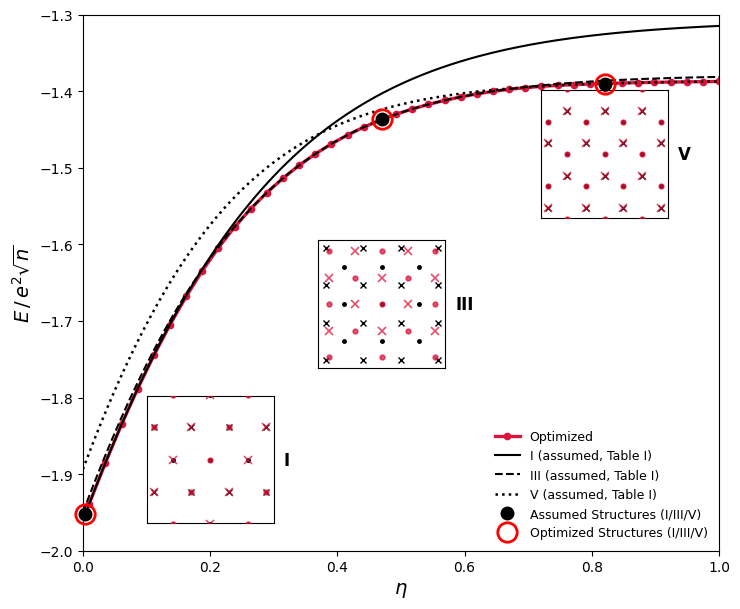

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 6.2))

# Draw red first, at the lowest z-order, so the black assumed curves are drawn
# on top of it -- wherever the optimized curve truly overlaps a black curve it
# will be hidden underneath, and any real deviation will visibly poke out from
# behind the black line.
ax.plot(
    eta_opt, energies_opt,
    ls="-", lw=2.4, color="crimson",
    marker="o", ms=4.5, mfc="crimson", mec="crimson",
    label="Optimized", zorder=1,
)

ax.plot(eta_vals, energies_ref["I"], color="black", ls="-", lw=1.5, label="I (assumed, Table I)", zorder=3)
ax.plot(eta_vals, energies_ref["III"], color="black", ls="--", lw=1.5, label="III (assumed, Table I)", zorder=3)
ax.plot(eta_vals, energies_ref["V"], color="black", ls=":", lw=1.8, label="V (assumed, Table I)", zorder=3)

ax.set_xlim(0.0, 1.0)
ax.set_ylim(-2.0, -1.3)
ax.set_xlabel(r"$\eta$", fontsize=14)
ax.set_ylabel(r"$E\,/\,e^2\sqrt{n}$", fontsize=14)

inset_I = add_lattice_inset(ax, bounds_I, "I")
inset_right_edge_label(ax, bounds_I, "I")
inset_III = add_lattice_inset(ax, bounds_III, "III")
inset_right_edge_label(ax, bounds_III, "III")
inset_V = add_lattice_inset(ax, bounds_V, "V")
inset_right_edge_label(ax, bounds_V, "V")

# Overlay the ACTUAL optimized structure (cell + 2 relaxed electron positions) at
# each of these same three eta values, directly on top of the black assumed
# inset it should match -- a genuine geometry check, not just an energy check.
inset_axes_by_phase = {"I": inset_I, "III": inset_III, "V": inset_V}
eta_by_phase = dict(marker_points)
structure_key = jax.random.PRNGKey(2024)
optimized_structures = {}
marker_energies = {}
for phase in ["I", "III", "V"]:
    structure_key, subkey = jax.random.split(structure_key)
    RA, RB, cell_opt, e_marker = optimized_lattice_patch(eta_by_phase[phase], subkey)
    optimized_structures[phase] = (RA, RB, cell_opt)
    marker_energies[phase] = e_marker
    inset = inset_axes_by_phase[phase]
    inset.plot(*RA.T, ls="", marker=".", color="crimson", ms=7, alpha=0.75, zorder=4)
    inset.plot(*RB.T, ls="", marker="x", color="crimson", ms=6, mew=1.2, alpha=0.75, zorder=4)

# Filled black circles: the exact (eta, E) point on each ASSUMED curve that the
# black inset's Table-I geometry was pulled from.
ax.plot(
    eta_markers, E_markers,
    ls="", marker="o", ms=9, mfc="black", mec="black", mew=1.0, zorder=6, clip_on=False,
    label="Assumed Structures (I/III/V)",
)

# Red open circles: the exact (eta, E) point on the OPTIMIZED curve that each
# inset's red "actual optimized structure" overlay above was pulled from.
opt_marker_eta = [eta_by_phase[p] for p in ["I", "III", "V"]]
opt_marker_E = [marker_energies[p] for p in ["I", "III", "V"]]
ax.plot(
    opt_marker_eta, opt_marker_E,
    ls="", marker="o", ms=14, mfc="none", mec="red", mew=2.0, zorder=7, clip_on=False,
    label="Optimized Structures (I/III/V)",
)

ax.legend(frameon=False, loc="lower right", fontsize=9)

fig.tight_layout()

## 9. Do the optimized structures match the assumed lattices?

First, the raw cell vectors of the optimized structure next to the Table I cell at each inset $\eta$:

In [12]:
print(f"{'phase':6s} {'eta':>6s}   {'optimized a1':>22s}   {'optimized a2':>22s}   assumed a1 / a2 (Table I)")
for phase in ["I", "III", "V"]:
    eta = eta_by_phase[phase]
    _, _, cell_opt = optimized_structures[phase]
    latvec_ref, c_ref, a_ref = build_phase_cell(phase, n_total=1.0)
    print(f"{phase:6s} {eta:6.3f}   a1={cell_opt[0]}   a2={cell_opt[1]}   "
          f"ref a1={latvec_ref[0]}  a2={latvec_ref[1]}")

phase     eta             optimized a1             optimized a2   assumed a1 / a2 (Table I)
I       0.004   a1=[2.149105 0.      ]   a2=[0.537329 0.93062 ]   ref a1=[1.07457 0.     ]  a2=[0.      1.86121]
III     0.470   a1=[2.000045 0.      ]   a2=[1.000057 0.999978]   ref a1=[1.414214 0.      ]  a2=[0.       1.414214]
V       0.820   a1=[1.519672 0.      ]   a2=[0.759836 1.316074]   ref a1=[1.519671 0.      ]  a2=[0.759836 1.316074]


Looking at the inset overlays from the run shown here (the exact orientation and offset of the red pattern can vary from run to run): phase **V**'s red points land almost exactly on the black ones, and phase **III**'s look shifted/rotated but have the same density and pattern. Phase **I**'s red points also coincide with the black ones in position, but not always by layer: at some sites a red cross sits on a black dot or a red dot on a black cross, because the optimized lattice here is rotated by $60°$ from the Table I orientation. We check these observations quantitatively.

For I, III and V we expect a match up to rotation: nothing in our parameterization anchors the lattice to a particular compass direction, and Coulomb energy is rotationally invariant, so the optimizer is free to land on the same physical lattice at any overall orientation, whereas Table I of the paper tabulates one specific (axis-aligned) orientation. We check this with 2D lattice ("Lagrange") reduction, which puts any basis into a canonical shortest-vectors form independent of the original (possibly rotated/skewed) choice of primitive vectors:

In [13]:
def lagrange_reduce(cell):
    '''Canonical shortest-vectors basis of a 2D lattice (rotation/choice independent).'''
    a, b = np.array(cell[0], dtype=float), np.array(cell[1], dtype=float)
    while True:
        if np.linalg.norm(b) < np.linalg.norm(a):
            a, b = b, a
        m = round(np.dot(a, b) / np.dot(a, a))
        if m == 0:
            break
        b = b - m * a
    return a, b

print(f"{'phase':6s} {'|a| optimized':>14s} {'|b| optimized':>14s} {'angle':>8s}   "
      f"{'|a| reference':>14s} {'|b| reference':>14s} {'angle':>8s}")
for phase in ["I", "III", "V"]:
    _, _, cell_opt = optimized_structures[phase]
    latvec_ref, _, _ = build_phase_cell(phase, n_total=1.0)
    a1, b1 = lagrange_reduce(cell_opt)
    a2, b2 = lagrange_reduce(latvec_ref)
    ang1 = np.degrees(np.arccos(np.clip(np.dot(a1, b1) / np.linalg.norm(a1) / np.linalg.norm(b1), -1, 1)))
    ang2 = np.degrees(np.arccos(np.clip(np.dot(a2, b2) / np.linalg.norm(a2) / np.linalg.norm(b2), -1, 1)))
    print(f"{phase:6s} {np.linalg.norm(a1):14.5f} {np.linalg.norm(b1):14.5f} {ang1:8.3f}   "
          f"{np.linalg.norm(a2):14.5f} {np.linalg.norm(b2):14.5f} {ang2:8.3f}")

phase   |a| optimized  |b| optimized    angle    |a| reference  |b| reference    angle
I             1.07461        1.86115   90.000          1.07457        1.86121   90.000
III           1.41419        1.41424   89.997          1.41421        1.41421   90.000
V             1.51967        1.51967  120.000          1.51967        1.51967   60.000


In [14]:
def interlayer_distances(cell, shift, n=4, nrep=3):
    '''In-plane distances from a layer-A electron to its n nearest layer-B electrons, which are
    independent of the lattice's orientation.'''
    ii, jj = np.meshgrid(np.arange(-nrep, nrep + 1), np.arange(-nrep, nrep + 1))
    ij = np.stack([ii.ravel(), jj.ravel()], axis=-1)
    return np.sort(np.linalg.norm(ij @ cell + shift, axis=1))[:n]

print(f"{'phase':6s} {'optimized layer-B distances':>32s}   {'reference layer-B distances':>32s}")
for phase in ["I", "III", "V"]:
    RA, RB, cell_opt = optimized_structures[phase]
    latvec_ref, c_ref, _ = build_phase_cell(phase, n_total=1.0)
    print(f"{phase:6s} {str(interlayer_distances(cell_opt, RB[0] - RA[0])):>32s}   "
          f"{str(interlayer_distances(latvec_ref, c_ref)):>32s}")

phase       optimized layer-B distances        reference layer-B distances
I      [1.074552 1.074552 1.074552 1.074553]   [1.07457 1.07457 1.07457 1.07457]
III    [0.999978 0.999978 1.000022 1.000022]                      [1. 1. 1. 1.]
V      [0.877382 0.877383 0.877383 1.754765]   [0.877383 0.877383 0.877383 1.754765]


**I, III and V all check out**: once reduced to canonical form, the optimized and Table I lattice vector lengths and angles agree closely (typically to several significant figures) — the red pattern really is the same Bravais lattice as the black one, at most at a different (energy-irrelevant) orientation. (For V the reduced angles can read 120° in one and 60° in the other, which describe the same hexagonal lattice.)

Phase I has to be tested inside its own narrow stability window, $\eta<0.006$ (Sec. I and Fig. 5 of the paper), which is why its marker sits at $\eta=0.004$: above that window the soft phase II takes over and the aspect ratio moves away from the Table I value $|b|/|a|=\sqrt3\approx1.73$. Reduced lattice vectors do not describe how the two layers sit relative to each other, so the second table above lists the distances from a layer-A electron to its nearest layer-B electrons, which are independent of orientation; these agree as well, so each layer has been recovered and not just the combined pattern of points. We can also confirm directly that the optimizer's energy at this $\eta$ matches the assumed phase I energy:

In [15]:
eta_I_inset = eta_by_phase["I"]
e_assumed_I = reference_dimensionless_energy("I", eta_I_inset)
e_optimized_I, _, _ = optimize_eta(eta_I_inset, jax.random.PRNGKey(2024))
print(f"eta={eta_I_inset:.3f}   assumed phase I = {e_assumed_I:.6f}   "
      f"optimized (unconstrained) = {e_optimized_I:.6f}   "
      f"difference {e_assumed_I - e_optimized_I:.1e}")

eta=0.004   assumed phase I = -1.951672   optimized (unconstrained) = -1.951672   difference 9.7e-09


## 10. Discussion: the optimizer also finds the soft phases

The optimized curve — obtained with no phase table, no lattice type, and no interlayer displacement ever specified by hand — falls essentially on top of the assumed I/III/V curves across the whole $\eta$ range. In the two ranges where the paper finds the *soft* phases II (staggered rectangular) and IV (staggered rhombic) to be the true ground state — roughly $0.006<\eta<0.262$ and $0.622<\eta<0.732$ — it should sit slightly *below* the best of the three rigid curves, because II and IV have a continuously variable aspect ratio/angle that the rigid Table I geometries do not include. Our parameterization is a fully general fixed-area oblique cell, so the optimizer is free to relax into any aspect ratio or angle without being told these phases exist. The gap is small (the paper itself notes that phases II and IV are "nearly indistinguishable" from I/III/V on the scale of its Fig. 1), but at an interior point of each range it is measurable and in the direction of lower energy:

In [16]:
for eta in [0.1, 0.65]:
    key, subkey = jax.random.split(key)
    e_opt, _, _ = optimize_eta(eta, subkey)
    e_rigid = min(reference_dimensionless_energy(p, eta) for p in PHASE_TABLE)
    print(f"eta={eta:.2f}   optimized={e_opt:.5f}   best of I/III/V={e_rigid:.5f}   "
          f"optimized is lower by {e_rigid - e_opt:.5f}")

eta=0.10   optimized=-1.76429   best of I/III/V=-1.76408   optimized is lower by 0.00020
eta=0.65   optimized=-1.39974   best of I/III/V=-1.39960   optimized is lower by 0.00015


This is the payoff of not hardcoding the cell: the same optimization loop that reproduces the three rigid phases, with no extra code, also finds the lower energy of the two soft phases that a fixed table of rigid lattices cannot represent — purely by letting gradient descent explore the space of 2D bilayer lattices at each interlayer-distance-to-density ratio. (Only the energies are compared here; the II/IV lattice parameters themselves are not extracted.)

## Conclusion

Given nothing but two arbitrary starting positions and a value of $\eta$ — no phase table, no
lattice type, and no interlayer displacement specified by hand — gradient-based optimization
follows the lowest-energy structure across the full $\eta$ range. The structures themselves also
check out: at $\eta=0.004$, $0.47$ and $0.82$, inside the stability ranges of phases I, III and V
respectively, the optimized and Table I lattice vectors and layer offsets agree once compared in
a canonical (orientation-independent) form. Where the paper's *soft* phases II and IV become the ground state, the same
unconstrained optimizer finds a measurably lower energy than any of the rigid Table I geometries,
purely by exploring the space of general 2D bilayer lattices — a result the fixed rigid-lattice
table cannot represent on its own.